# Annotator Agreement Analysis

Evaluates inter-annotator agreement for:
1. **Human annotators** (3 experts, `an1.csv`, `an2.csv`, `an3.csv`) — overall and per language
2. **LLM judges** (OpenAI, Gemini, Qwen) — overall and per language
3. **LLM judges vs Human annotators** — on common samples
4. **Other judge numbers** — three-way disagreements, missing labels, single judge vs. experts

Labels for both human and LLM are resolved via **majority vote** before cross-group comparison.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import cohen_kappa_score, confusion_matrix
from itertools import combinations
import os
import glob
import re
import warnings
warnings.filterwarnings('ignore')

try:
    from statsmodels.stats.inter_rater import fleiss_kappa, aggregate_raters
    HAS_STATSMODELS = True
except ImportError:
    HAS_STATSMODELS = False
    print('statsmodels not installed — Fleiss kappa skipped')

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
sns.set_style('whitegrid')

LABEL_ORDER = ['CORRECT', 'INCORRECT', 'ABSTAIN']
VALID_LABELS = set(LABEL_ORDER)
LABEL_COLORS = {'CORRECT': '#27ae60', 'INCORRECT': '#e74c3c', 'ABSTAIN': '#3498db'}

DATA_DIR = '../data'
ANNOTATION_DIR = f'{DATA_DIR}/expert_annotation'
JUDGE_DIR = f'{DATA_DIR}/judge step'

In [2]:
def majority_vote(labels):
    """Return majority label. Tie-break: ABSTAIN > CORRECT > INCORRECT."""
    counts = pd.Series(labels).value_counts()
    max_count = counts.max()
    top = counts[counts == max_count].index.tolist()
    if len(top) == 1:
        return top[0]
    for priority in ['ABSTAIN', 'CORRECT', 'INCORRECT']:
        if priority in top:
            return priority
    return top[0]


def _binarize(series, pos_label):
    """Map a label series to pos_label vs 'OTHER'."""
    return series.map(lambda x: pos_label if x == pos_label else 'OTHER')


def compute_agreement_metrics(df, label_cols):
    """
    Returns a dict with:
      - pairwise Cohen's kappas (3-class)
      - mean_pairwise_kappa
      - fleiss_kappa
      - pct_full_agreement
      - mean_kappa_abstain_vs_answered  (binary: ABSTAIN vs rest)
      - mean_kappa_correct_vs_incorrect (binary: on non-ABSTAIN pairs only)
    """
    label_map = {'CORRECT': 0, 'INCORRECT': 1, 'ABSTAIN': 2}
    metrics = {}

    pairs = list(combinations(label_cols, 2))
    kappas, kappas_ab, kappas_ci = [], [], []

    for col_a, col_b in pairs:
        # 3-class kappa
        try:
            k = cohen_kappa_score(df[col_a], df[col_b])
        except Exception:
            k = np.nan
        kappas.append(k)
        metrics[f'kappa_{col_a}_vs_{col_b}'] = k

        # Binary: ABSTAIN vs ANSWERED
        try:
            k_ab = cohen_kappa_score(_binarize(df[col_a], 'ABSTAIN'),
                                     _binarize(df[col_b], 'ABSTAIN'))
        except Exception:
            k_ab = np.nan
        kappas_ab.append(k_ab)

        # Binary: CORRECT vs INCORRECT — non-ABSTAIN pairs only
        mask = (df[col_a] != 'ABSTAIN') & (df[col_b] != 'ABSTAIN')
        sub = df[mask]
        try:
            k_ci = cohen_kappa_score(sub[col_a], sub[col_b]) if len(sub) >= 2 else np.nan
        except Exception:
            k_ci = np.nan
        kappas_ci.append(k_ci)

    metrics['mean_pairwise_kappa']           = np.nanmean(kappas)
    metrics['mean_kappa_abstain_vs_answered']  = np.nanmean(kappas_ab)
    metrics['mean_kappa_correct_vs_incorrect'] = np.nanmean(kappas_ci)

    if HAS_STATSMODELS:
        ratings = df[label_cols].apply(lambda col: col.map(label_map))
        valid = ratings.notna().all(axis=1)
        r = ratings[valid].astype(int)
        try:
            agg = aggregate_raters(r.values)[0]
            metrics['fleiss_kappa'] = fleiss_kappa(agg)
        except Exception:
            metrics['fleiss_kappa'] = np.nan
    else:
        metrics['fleiss_kappa'] = np.nan

    if len(label_cols) >= 2:
        metrics['pct_full_agreement'] = (df[label_cols].nunique(axis=1) == 1).mean()

    return metrics


def binary_kappas(s1, s2):
    """Compute ABSTAIN-vs-ANSWERED and CORRECT-vs-INCORRECT kappas for two label series."""
    try:
        k_ab = cohen_kappa_score(_binarize(s1, 'ABSTAIN'), _binarize(s2, 'ABSTAIN'))
    except Exception:
        k_ab = np.nan
    mask = (s1 != 'ABSTAIN') & (s2 != 'ABSTAIN')
    try:
        k_ci = cohen_kappa_score(s1[mask], s2[mask]) if mask.sum() >= 2 else np.nan
    except Exception:
        k_ci = np.nan
    return k_ab, k_ci

## Human Expert Annotator Agreement

In [3]:
ANNOTATION_COLS = [
    'model', 'prompt_variant', 'language', 'query_id', 'doc_id',
    'difficulty', 'query', 'generated_answer', 'gold_answer', 'label'
]
HUMAN_ID_COLS = ['model', 'prompt_variant', 'language', 'query_id', 'doc_id', 'difficulty']

annotator_dfs = {}
for i in range(1, 4):
    df = pd.read_csv(f'{ANNOTATION_DIR}/an{i}.csv', header=None, names=ANNOTATION_COLS)
    df = df[df['label'].isin(VALID_LABELS)].copy()
    df['query_id'] = df['query_id'].astype(str)
    df['doc_id'] = df['doc_id'].astype(str)
    annotator_dfs[f'an{i}'] = df
    print(f'an{i}: {len(df):,} rows | labels: {df["label"].value_counts().to_dict()}')

print(f'\nLanguages: {sorted(annotator_dfs["an1"]["language"].unique())}')
print(f'Models:    {sorted(annotator_dfs["an1"]["model"].unique())}')

an1: 2,396 rows | labels: {'ABSTAIN': 1722, 'INCORRECT': 440, 'CORRECT': 234}
an2: 2,400 rows | labels: {'ABSTAIN': 1734, 'INCORRECT': 430, 'CORRECT': 236}
an3: 2,400 rows | labels: {'ABSTAIN': 1730, 'INCORRECT': 466, 'CORRECT': 204}

Languages: ['en', 'ru']
Models:    ['gemma4', 'gpt54mini']


In [4]:
# Inner-join all three annotators on shared ID columns
human_merged = (
    annotator_dfs['an1'][HUMAN_ID_COLS + ['label']]
    .rename(columns={'label': 'label_an1'})
    .merge(
        annotator_dfs['an2'][HUMAN_ID_COLS + ['label']].rename(columns={'label': 'label_an2'}),
        on=HUMAN_ID_COLS
    )
    .merge(
        annotator_dfs['an3'][HUMAN_ID_COLS + ['label']].rename(columns={'label': 'label_an3'}),
        on=HUMAN_ID_COLS
    )
)

HUMAN_LABEL_COLS = ['label_an1', 'label_an2', 'label_an3']

human_merged['majority_label'] = human_merged[HUMAN_LABEL_COLS].apply(
    lambda r: majority_vote(r.tolist()), axis=1
)
human_merged['full_agreement'] = human_merged[HUMAN_LABEL_COLS].nunique(axis=1) == 1

print(f'Common samples across all 3 annotators: {len(human_merged):,}')
print(f'Full agreement rate: {human_merged["full_agreement"].mean():.1%}')
print(f'\nMajority vote distribution:')
print(human_merged['majority_label'].value_counts())

Common samples across all 3 annotators: 2,396
Full agreement rate: 90.2%

Majority vote distribution:
majority_label
ABSTAIN      1731
INCORRECT     443
CORRECT       222
Name: count, dtype: int64


In [5]:
print('=' * 60)
print('OVERALL HUMAN ANNOTATOR AGREEMENT')
print('=' * 60)

human_overall = compute_agreement_metrics(human_merged, HUMAN_LABEL_COLS)

for col_a, col_b in combinations(HUMAN_LABEL_COLS, 2):
    k = human_overall[f'kappa_{col_a}_vs_{col_b}']
    a, b = col_a.replace('label_', '').upper(), col_b.replace('label_', '').upper()
    print(f"  Cohen's Kappa ({a} vs {b}): {k:.4f}")

print(f"\n  Mean Pairwise Kappa (3-class)    : {human_overall['mean_pairwise_kappa']:.4f}")
print(f"  Fleiss' Kappa                    : {human_overall.get('fleiss_kappa', float('nan')):.4f}")
print(f"  Full Agreement Rate              : {human_overall.get('pct_full_agreement', float('nan')):.1%}")
print(f"\n  ── Binary sub-tasks ──")
print(f"  κ  ABSTAIN vs ANSWERED           : {human_overall['mean_kappa_abstain_vs_answered']:.4f}")
print(f"  κ  CORRECT vs INCORRECT          : {human_overall['mean_kappa_correct_vs_incorrect']:.4f}  (non-ABSTAIN pairs only)")

OVERALL HUMAN ANNOTATOR AGREEMENT
  Cohen's Kappa (AN1 vs AN2): 0.8514
  Cohen's Kappa (AN1 vs AN3): 0.8322
  Cohen's Kappa (AN2 vs AN3): 0.8611

  Mean Pairwise Kappa (3-class)    : 0.8482
  Fleiss' Kappa                    : 0.8482
  Full Agreement Rate              : 90.2%

  ── Binary sub-tasks ──
  κ  ABSTAIN vs ANSWERED           : 0.9530
  κ  CORRECT vs INCORRECT          : 0.6076  (non-ABSTAIN pairs only)


In [6]:
lang_human_rows = []
for lang in sorted(human_merged['language'].unique()):
    sub = human_merged[human_merged['language'] == lang]
    m = compute_agreement_metrics(sub, HUMAN_LABEL_COLS)
    lang_human_rows.append({
        'language': lang,
        'n': len(sub),
        'full_agr_%': sub['full_agreement'].mean() * 100,
        'mean_pairwise_k': m['mean_pairwise_kappa'],
        'fleiss_k': m.get('fleiss_kappa', np.nan),
        'k_abstain_vs_ans': m['mean_kappa_abstain_vs_answered'],
        'k_corr_vs_incorr': m['mean_kappa_correct_vs_incorrect'],
    })

lang_human_df = pd.DataFrame(lang_human_rows).set_index('language')
print('Per-Language Human Agreement:')
print(lang_human_df.round(4).to_string())

Per-Language Human Agreement:
             n  full_agr_%  mean_pairwise_k  fleiss_k  k_abstain_vs_ans  k_corr_vs_incorr
language                                                                                 
en        1197     88.3041           0.8360    0.8359            0.9536            0.5989
ru        1199     92.0767           0.8614    0.8614            0.9515            0.6021


In [7]:
diff_human_rows = []
for diff in ['easy', 'medium', 'hard']:
    sub = human_merged[human_merged['difficulty'] == diff]
    if len(sub) == 0:
        continue
    m = compute_agreement_metrics(sub, HUMAN_LABEL_COLS)
    diff_human_rows.append({
        'difficulty': diff,
        'n': len(sub),
        'full_agr_%': sub['full_agreement'].mean() * 100,
        'mean_pairwise_k': m['mean_pairwise_kappa'],
        'fleiss_k': m.get('fleiss_kappa', np.nan),
        'k_abstain_vs_ans': m['mean_kappa_abstain_vs_answered'],
        'k_corr_vs_incorr': m['mean_kappa_correct_vs_incorrect'],
    })

diff_human_df = pd.DataFrame(diff_human_rows).set_index('difficulty')
print('Per-Difficulty Human Agreement:')
print(diff_human_df.round(4).to_string())

Per-Difficulty Human Agreement:
              n  full_agr_%  mean_pairwise_k  fleiss_k  k_abstain_vs_ans  k_corr_vs_incorr
difficulty                                                                                
easy        798     93.4837           0.8720    0.8719            0.9524            0.5926
medium      799     89.3617           0.8450    0.8451            0.9483            0.6055
hard        799     87.7347           0.8305    0.8305            0.9564            0.5882


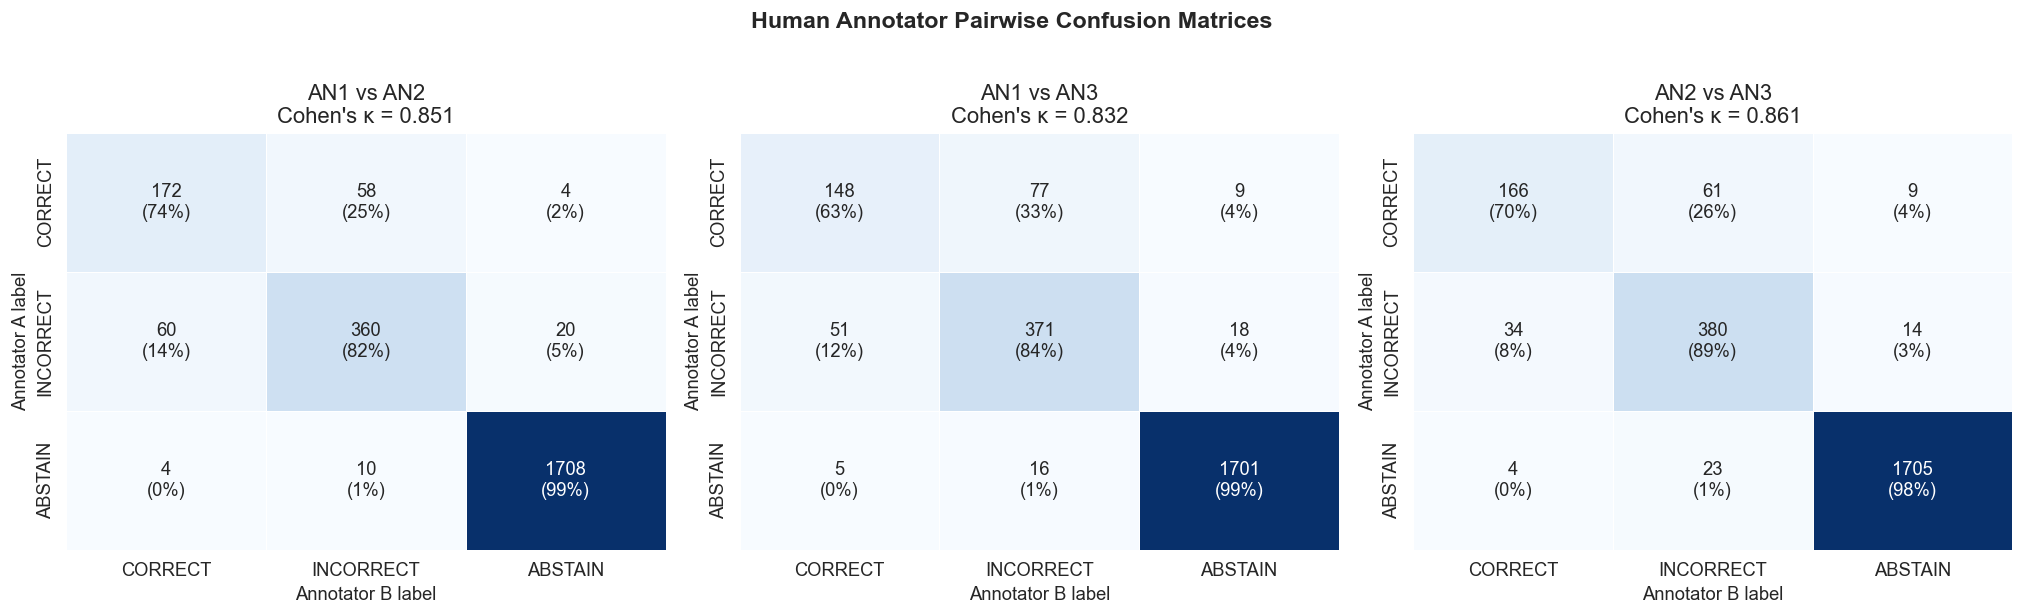

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
pair_specs = [
    ('label_an1', 'label_an2', 'AN1 vs AN2'),
    ('label_an1', 'label_an3', 'AN1 vs AN3'),
    ('label_an2', 'label_an3', 'AN2 vs AN3'),
]

for ax, (col_a, col_b, title) in zip(axes, pair_specs):
    cm = confusion_matrix(human_merged[col_a], human_merged[col_b], labels=LABEL_ORDER)
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_pct = np.where(row_sums > 0, cm / row_sums * 100, 0)
    annot = np.vectorize(lambda c, p: f'{c}\n({p:.0f}%)')( cm, cm_pct)
    sns.heatmap(
        cm, annot=annot, fmt='', xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER,
        cmap='Blues', ax=ax, linewidths=0.5, cbar=False
    )
    k_key = f'kappa_{col_a}_vs_{col_b}'
    k = human_overall.get(k_key, np.nan)
    ax.set_title(f"{title}\nCohen's κ = {k:.3f}")
    ax.set_xlabel('Annotator B label')
    ax.set_ylabel('Annotator A label')

plt.suptitle('Human Annotator Pairwise Confusion Matrices', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## LLM Judge Agreement

In [9]:
PROVIDERS = ['openai', 'gemini', 'qwen']
JUDGE_ID_COLS = ['language', 'query_id', 'distractor_id']
JUDGE_LABEL_COLS = [f'label_{p}' for p in PROVIDERS]

files_by_provider = {}
for provider in PROVIDERS:
    pdir = f'{JUDGE_DIR}/{provider}'
    flist = glob.glob(f'{pdir}/*.csv')
    files_by_provider[provider] = {os.path.basename(f): f for f in sorted(flist)}
    print(f'{provider}: {len(flist)} files')

common_files = set(files_by_provider[PROVIDERS[0]])
for p in PROVIDERS[1:]:
    common_files &= set(files_by_provider[p])

print(f'\nFiles common to all 3 providers: {len(common_files)}')
for f in sorted(common_files):
    print(f'  {f}')

openai: 10 files
gemini: 10 files
qwen: 10 files

Files common to all 3 providers: 10
  multilingual_claude_sonnet4_answers__judged.csv
  multilingual_claude_sonnet4_answers_advanced__judged.csv
  multilingual_gemini31_flash_lite_answers__judged.csv
  multilingual_gemini31_flash_lite_answers_advanced__judged.csv
  multilingual_gemma4_answers__judged.csv
  multilingual_gemma4_answers_advanced__judged.csv
  multilingual_gpt54mini_answers__judged.csv
  multilingual_gpt54mini_answers_advanced__judged.csv
  multilingual_qwen36_answers__judged.csv
  multilingual_qwen36_answers_advanced__judged.csv


In [10]:
all_merged = []

for fname in sorted(common_files):
    provider_dfs = {}
    for provider in PROVIDERS:
        fpath = files_by_provider[provider][fname]
        df = pd.read_csv(fpath)
        df = df[df['judge_label'].isin(VALID_LABELS)].copy()
        df['query_id'] = df['query_id'].astype(str)
        df['distractor_id'] = df['distractor_id'].astype(str)
        provider_dfs[provider] = df[JUDGE_ID_COLS + ['difficulty', 'judge_label']]

    merged = provider_dfs[PROVIDERS[0]].rename(columns={'judge_label': f'label_{PROVIDERS[0]}'})
    for provider in PROVIDERS[1:]:
        merged = merged.merge(
            provider_dfs[provider][JUDGE_ID_COLS + ['judge_label']].rename(
                columns={'judge_label': f'label_{provider}'}
            ),
            on=JUDGE_ID_COLS
        )
    merged['source_file'] = fname
    all_merged.append(merged)

judge_merged = pd.concat(all_merged, ignore_index=True)

judge_merged['majority_label'] = judge_merged[JUDGE_LABEL_COLS].apply(
    lambda r: majority_vote(r.tolist()), axis=1
)
judge_merged['full_agreement'] = judge_merged[JUDGE_LABEL_COLS].nunique(axis=1) == 1

print(f'Total merged judge rows: {len(judge_merged):,}')
print(f'Full agreement rate: {judge_merged["full_agreement"].mean():.1%}')
print(f'\nMajority vote distribution:')
print(judge_merged['majority_label'].value_counts())

Total merged judge rows: 41,971
Full agreement rate: 94.6%

Majority vote distribution:
majority_label
ABSTAIN      30310
INCORRECT     8798
CORRECT       2863
Name: count, dtype: int64


In [11]:
print('=' * 60)
print('OVERALL LLM JUDGE AGREEMENT')
print('=' * 60)

judge_overall = compute_agreement_metrics(judge_merged, JUDGE_LABEL_COLS)

for col_a, col_b in combinations(JUDGE_LABEL_COLS, 2):
    k = judge_overall[f'kappa_{col_a}_vs_{col_b}']
    a, b = col_a.replace('label_', '').upper(), col_b.replace('label_', '').upper()
    print(f"  Cohen's Kappa ({a} vs {b}): {k:.4f}")

print(f"\n  Mean Pairwise Kappa (3-class)    : {judge_overall['mean_pairwise_kappa']:.4f}")
print(f"  Fleiss' Kappa                    : {judge_overall.get('fleiss_kappa', float('nan')):.4f}")
print(f"  Full Agreement Rate              : {judge_overall.get('pct_full_agreement', float('nan')):.1%}")
print(f"\n  ── Binary sub-tasks ──")
print(f"  κ  ABSTAIN vs ANSWERED           : {judge_overall['mean_kappa_abstain_vs_answered']:.4f}")
print(f"  κ  CORRECT vs INCORRECT          : {judge_overall['mean_kappa_correct_vs_incorrect']:.4f}  (non-ABSTAIN pairs only)")

OVERALL LLM JUDGE AGREEMENT


  Cohen's Kappa (OPENAI vs GEMINI): 0.9072
  Cohen's Kappa (OPENAI vs QWEN): 0.9171
  Cohen's Kappa (GEMINI vs QWEN): 0.9274

  Mean Pairwise Kappa (3-class)    : 0.9172
  Fleiss' Kappa                    : 0.9172
  Full Agreement Rate              : 94.6%

  ── Binary sub-tasks ──
  κ  ABSTAIN vs ANSWERED           : 0.9580
  κ  CORRECT vs INCORRECT          : 0.8155  (non-ABSTAIN pairs only)


In [12]:
lang_judge_rows = []
for lang in sorted(judge_merged['language'].unique()):
    sub = judge_merged[judge_merged['language'] == lang]
    m = compute_agreement_metrics(sub, JUDGE_LABEL_COLS)
    lang_judge_rows.append({
        'language': lang,
        'n': len(sub),
        'full_agr_%': sub['full_agreement'].mean() * 100,
        'mean_pairwise_k': m['mean_pairwise_kappa'],
        'fleiss_k': m.get('fleiss_kappa', np.nan),
        'k_abstain_vs_ans': m['mean_kappa_abstain_vs_answered'],
        'k_corr_vs_incorr': m['mean_kappa_correct_vs_incorrect'],
    })

lang_judge_df = pd.DataFrame(lang_judge_rows).set_index('language')
print('Per-Language LLM Judge Agreement:')
print(lang_judge_df.round(4).to_string())

Per-Language LLM Judge Agreement:
             n  full_agr_%  mean_pairwise_k  fleiss_k  k_abstain_vs_ans  k_corr_vs_incorr
language                                                                                 
ar        3000     89.8000           0.8686    0.8684            0.8999            0.8544
de        3000     93.9000           0.9087    0.9085            0.9432            0.8273
en        3000     97.5333           0.9575    0.9575            0.9856            0.8779
es        3000     94.8333           0.9047    0.9046            0.9346            0.7878
fa        2984     93.3646           0.9122    0.9121            0.9497            0.7771
fi        2995     93.7896           0.8975    0.8973            0.9507            0.7816
fr        2993     92.4825           0.9073    0.9073            0.9546            0.7223
hi        3000     97.1000           0.9423    0.9423            0.9793            0.8405
id        3000     95.5000           0.9212    0.9212            0

In [13]:
diff_judge_rows = []
for diff in ['easy', 'medium', 'hard']:
    sub = judge_merged[judge_merged['difficulty'] == diff]
    if len(sub) == 0:
        continue
    m = compute_agreement_metrics(sub, JUDGE_LABEL_COLS)
    diff_judge_rows.append({
        'difficulty': diff,
        'n': len(sub),
        'full_agr_%': sub['full_agreement'].mean() * 100,
        'mean_pairwise_k': m['mean_pairwise_kappa'],
        'fleiss_k': m.get('fleiss_kappa', np.nan),
        'k_abstain_vs_ans': m['mean_kappa_abstain_vs_answered'],
        'k_corr_vs_incorr': m['mean_kappa_correct_vs_incorrect'],
    })

diff_judge_df = pd.DataFrame(diff_judge_rows).set_index('difficulty')
print('Per-Difficulty LLM Judge Agreement:')
print(diff_judge_df.round(4).to_string())

Per-Difficulty LLM Judge Agreement:
                n  full_agr_%  mean_pairwise_k  fleiss_k  k_abstain_vs_ans  k_corr_vs_incorr
difficulty                                                                                  
easy        13994     96.4342           0.9222    0.9221            0.9409            0.8109
medium      13993     95.3691           0.9267    0.9266            0.9586            0.8342
hard        13984     92.1339           0.9023    0.9022            0.9648            0.7893


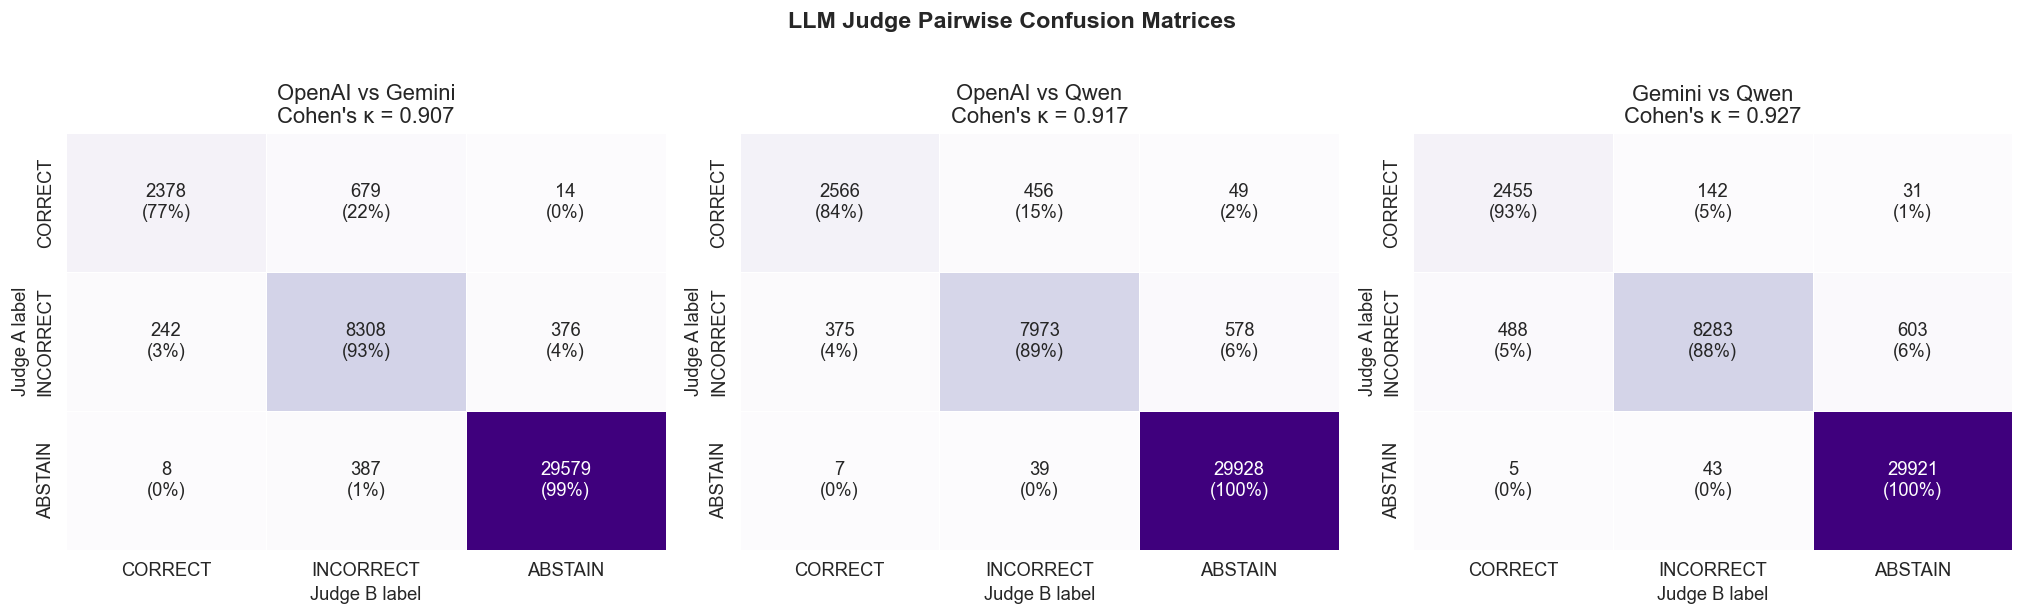

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
judge_pair_specs = [
    ('label_openai', 'label_gemini', 'OpenAI vs Gemini'),
    ('label_openai', 'label_qwen',   'OpenAI vs Qwen'),
    ('label_gemini', 'label_qwen',   'Gemini vs Qwen'),
]

for ax, (col_a, col_b, title) in zip(axes, judge_pair_specs):
    cm = confusion_matrix(judge_merged[col_a], judge_merged[col_b], labels=LABEL_ORDER)
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_pct = np.where(row_sums > 0, cm / row_sums * 100, 0)
    annot = np.vectorize(lambda c, p: f'{c}\n({p:.0f}%)')( cm, cm_pct)
    sns.heatmap(
        cm, annot=annot, fmt='', xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER,
        cmap='Purples', ax=ax, linewidths=0.5, cbar=False
    )
    k_key = f'kappa_{col_a}_vs_{col_b}'
    k = judge_overall.get(k_key, np.nan)
    ax.set_title(f"{title}\nCohen's κ = {k:.3f}")
    ax.set_xlabel('Judge B label')
    ax.set_ylabel('Judge A label')

plt.suptitle('LLM Judge Pairwise Confusion Matrices', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## LLM Judges vs Human Annotators

Match samples that appear in **both** the expert annotation data and the LLM judge data,
then compare **majority-vote** labels from each group.

In [15]:
def filename_to_model_pv(fname):
    """Extract (model_key, prompt_variant) from a judge output filename."""
    base = fname.replace('__judged.csv', '').replace('_judged.csv', '')
    pv = 'advanced' if 'advanced' in base else 'simple'

    m = re.match(r'multilingual_(.+?)_answers', base)
    if m:
        model = m.group(1)
    elif 'gemma4_26b' in base:
        model = 'gemma4_26b'
    elif 'qwen3' in base:
        model = 'qwen36'
    else:
        model = base
    return model, pv

fname_meta = {f: filename_to_model_pv(f) for f in judge_merged['source_file'].unique()}
judge_merged['model_key'] = judge_merged['source_file'].map(lambda f: fname_meta[f][0])
judge_merged['pv_key']    = judge_merged['source_file'].map(lambda f: fname_meta[f][1])

print('Judge file → (model_key, prompt_variant):')
for fname, (model, pv) in sorted(fname_meta.items()):
    print(f'  {fname:60s} → {model}, {pv}')

Judge file → (model_key, prompt_variant):
  multilingual_claude_sonnet4_answers__judged.csv              → claude_sonnet4, simple
  multilingual_claude_sonnet4_answers_advanced__judged.csv     → claude_sonnet4, advanced
  multilingual_gemini31_flash_lite_answers__judged.csv         → gemini31_flash_lite, simple
  multilingual_gemini31_flash_lite_answers_advanced__judged.csv → gemini31_flash_lite, advanced
  multilingual_gemma4_answers__judged.csv                      → gemma4, simple
  multilingual_gemma4_answers_advanced__judged.csv             → gemma4, advanced
  multilingual_gpt54mini_answers__judged.csv                   → gpt54mini, simple
  multilingual_gpt54mini_answers_advanced__judged.csv          → gpt54mini, advanced
  multilingual_qwen36_answers__judged.csv                      → qwen36, simple
  multilingual_qwen36_answers_advanced__judged.csv             → qwen36, advanced


In [16]:
expert_models = set(human_merged['model'].unique())
judge_models  = set(judge_merged['model_key'].unique())

print(f'Expert annotation model names: {sorted(expert_models)}')
print(f'Judge file model keys:         {sorted(judge_models)}')

# Auto-map by exact or substring match
MODEL_MAP = {}
for em in expert_models:
    if em in judge_models:
        MODEL_MAP[em] = em
    else:
        candidates = [jm for jm in judge_models if em in jm or jm in em]
        if candidates:
            MODEL_MAP[em] = candidates[0]

print(f'\nAuto-detected model mapping: {MODEL_MAP}')
# Override here if needed:
# MODEL_MAP['expert_name'] = 'judge_key'

Expert annotation model names: ['gemma4', 'gpt54mini']
Judge file model keys:         ['claude_sonnet4', 'gemini31_flash_lite', 'gemma4', 'gpt54mini', 'qwen36']

Auto-detected model mapping: {'gpt54mini': 'gpt54mini', 'gemma4': 'gemma4'}


In [17]:
# Prepare expert side
expert_side = human_merged[['model', 'prompt_variant', 'language', 'query_id',
                             'doc_id', 'difficulty', 'majority_label']].copy()
expert_side['model_key'] = expert_side['model'].map(MODEL_MAP)
expert_side = expert_side.dropna(subset=['model_key'])

# Prepare judge side (majority vote already computed)
judge_side = judge_merged[['model_key', 'pv_key', 'language', 'query_id',
                            'distractor_id', 'majority_label']].copy()
judge_side = judge_side.rename(columns={
    'pv_key': 'prompt_variant',
    'distractor_id': 'doc_id',
    'majority_label': 'judge_majority'
})

lvh = expert_side.merge(
    judge_side,
    on=['model_key', 'prompt_variant', 'language', 'query_id', 'doc_id']
).rename(columns={'majority_label': 'human_majority'})

print(f'Common samples (human ∩ LLM judge): {len(lvh):,}')
print(f'Languages: {sorted(lvh["language"].unique())}')
print(f'\nHuman majority vote distribution:\n{lvh["human_majority"].value_counts()}')
print(f'\nLLM majority vote distribution:\n{lvh["judge_majority"].value_counts()}')

Common samples (human ∩ LLM judge): 2,396
Languages: ['en', 'ru']

Human majority vote distribution:
human_majority
ABSTAIN      1731
INCORRECT     443
CORRECT       222
Name: count, dtype: int64

LLM majority vote distribution:
judge_majority
ABSTAIN      1746
INCORRECT     511
CORRECT       139
Name: count, dtype: int64


In [18]:
agr = (lvh['human_majority'] == lvh['judge_majority']).mean()
kappa_lvh = cohen_kappa_score(lvh['human_majority'], lvh['judge_majority'])
kappa_ab_lvh, kappa_ci_lvh = binary_kappas(lvh['human_majority'], lvh['judge_majority'])

print('=' * 60)
print('LLM JUDGES vs HUMAN ANNOTATORS')
print('=' * 60)
print(f'  Agreement Rate (3-class)         : {agr:.1%}')
print(f"  Cohen's Kappa  (3-class)         : {kappa_lvh:.4f}")
print(f"\n  ── Binary sub-tasks ──")
print(f"  κ  ABSTAIN vs ANSWERED           : {kappa_ab_lvh:.4f}")
print(f"  κ  CORRECT vs INCORRECT          : {kappa_ci_lvh:.4f}  (non-ABSTAIN pairs only)")

cm = confusion_matrix(lvh['human_majority'], lvh['judge_majority'], labels=LABEL_ORDER)
cm_df = pd.DataFrame(cm, index=pd.Index(LABEL_ORDER, name='Human'),
                         columns=pd.Index(LABEL_ORDER, name='LLM Judge'))
print('\nFull Confusion Matrix:')
print(cm_df)

# CORRECT vs INCORRECT sub-matrix (non-ABSTAIN pairs)
mask_non_abs = (lvh['human_majority'] != 'ABSTAIN') & (lvh['judge_majority'] != 'ABSTAIN')
lvh_non_abs = lvh[mask_non_abs]
cm_ci = confusion_matrix(lvh_non_abs['human_majority'], lvh_non_abs['judge_majority'],
                          labels=['CORRECT', 'INCORRECT'])
cm_ci_df = pd.DataFrame(cm_ci, index=pd.Index(['CORRECT', 'INCORRECT'], name='Human'),
                                columns=pd.Index(['CORRECT', 'INCORRECT'], name='LLM Judge'))
print(f'\nCORRECT vs INCORRECT sub-matrix (n={len(lvh_non_abs)}, both non-ABSTAIN):')
print(cm_ci_df)

LLM JUDGES vs HUMAN ANNOTATORS
  Agreement Rate (3-class)         : 93.9%
  Cohen's Kappa  (3-class)         : 0.8569

  ── Binary sub-tasks ──
  κ  ABSTAIN vs ANSWERED           : 0.9675
  κ  CORRECT vs INCORRECT          : 0.5554  (non-ABSTAIN pairs only)

Full Confusion Matrix:
LLM Judge  CORRECT  INCORRECT  ABSTAIN
Human                                 
CORRECT        119         96        7
INCORRECT       20        407       16
ABSTAIN          0          8     1723

CORRECT vs INCORRECT sub-matrix (n=642, both non-ABSTAIN):
LLM Judge  CORRECT  INCORRECT
Human                        
CORRECT        119         96
INCORRECT       20        407


In [19]:
lang_lvh_rows = []
for lang in sorted(lvh['language'].unique()):
    sub = lvh[lvh['language'] == lang]
    try:
        k = cohen_kappa_score(sub['human_majority'], sub['judge_majority'])
    except Exception:
        k = np.nan
    k_ab, k_ci = binary_kappas(sub['human_majority'], sub['judge_majority'])
    lang_lvh_rows.append({
        'language': lang,
        'n': len(sub),
        'agreement_%': (sub['human_majority'] == sub['judge_majority']).mean() * 100,
        'cohen_kappa': k,
        'k_abstain_vs_ans': k_ab,
        'k_corr_vs_incorr': k_ci,
    })

lang_lvh_df = pd.DataFrame(lang_lvh_rows).set_index('language')
print('Per-Language LLM vs Human Agreement:')
print(lang_lvh_df.round(4).to_string())

Per-Language LLM vs Human Agreement:
             n  agreement_%  cohen_kappa  k_abstain_vs_ans  k_corr_vs_incorr
language                                                                    
en        1197      91.4787       0.8195            0.9708            0.4638
ru        1199      96.2469       0.9017            0.9632            0.7017


In [20]:
diff_lvh_rows = []
for diff in ['easy', 'medium', 'hard']:
    sub = lvh[lvh['difficulty'] == diff]
    if len(sub) == 0:
        continue
    try:
        k = cohen_kappa_score(sub['human_majority'], sub['judge_majority'])
    except Exception:
        k = np.nan
    k_ab, k_ci = binary_kappas(sub['human_majority'], sub['judge_majority'])
    diff_lvh_rows.append({
        'difficulty': diff,
        'n': len(sub),
        'agreement_%': (sub['human_majority'] == sub['judge_majority']).mean() * 100,
        'cohen_kappa': k,
        'k_abstain_vs_ans': k_ab,
        'k_corr_vs_incorr': k_ci,
    })

diff_lvh_df = pd.DataFrame(diff_lvh_rows).set_index('difficulty')
print('Per-Difficulty LLM vs Human Agreement:')
print(diff_lvh_df.round(4).to_string())

Per-Difficulty LLM vs Human Agreement:
              n  agreement_%  cohen_kappa  k_abstain_vs_ans  k_corr_vs_incorr
difficulty                                                                   
easy        798      96.1153       0.8850            0.9579            0.4834
medium      799      92.2403       0.8274            0.9609            0.4579
hard        799      93.2416       0.8610            0.9799            0.6119


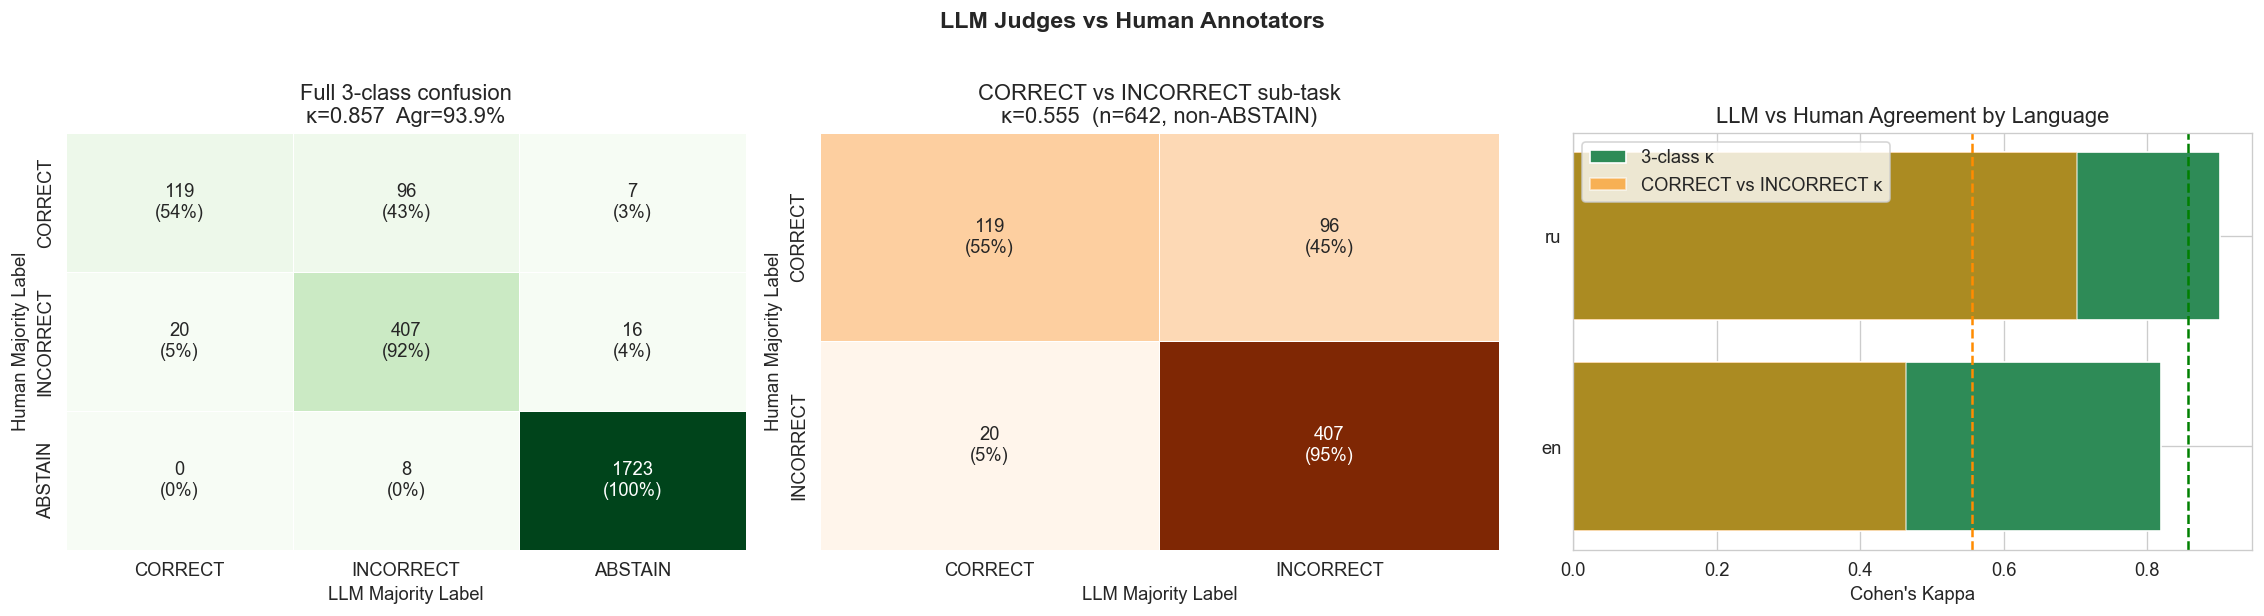

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Full 3-class confusion matrix
ax = axes[0]
row_sums = cm.sum(axis=1, keepdims=True)
cm_pct = np.where(row_sums > 0, cm / row_sums * 100, 0)
annot = np.vectorize(lambda c, p: f'{c}\n({p:.0f}%)')( cm, cm_pct)
sns.heatmap(
    cm, annot=annot, fmt='', xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER,
    cmap='Greens', ax=ax, linewidths=0.5, cbar=False
)
ax.set_title(f"Full 3-class confusion\nκ={kappa_lvh:.3f}  Agr={agr:.1%}")
ax.set_xlabel('LLM Majority Label')
ax.set_ylabel('Human Majority Label')

# CORRECT vs INCORRECT sub-matrix (non-ABSTAIN pairs)
ax = axes[1]
row_sums_ci = cm_ci.sum(axis=1, keepdims=True)
cm_ci_pct = np.where(row_sums_ci > 0, cm_ci / row_sums_ci * 100, 0)
annot_ci = np.vectorize(lambda c, p: f'{c}\n({p:.0f}%)')( cm_ci, cm_ci_pct)
sns.heatmap(
    cm_ci, annot=annot_ci, fmt='', xticklabels=['CORRECT', 'INCORRECT'],
    yticklabels=['CORRECT', 'INCORRECT'],
    cmap='Oranges', ax=ax, linewidths=0.5, cbar=False
)
ax.set_title(f"CORRECT vs INCORRECT sub-task\nκ={kappa_ci_lvh:.3f}  (n={len(lvh_non_abs)}, non-ABSTAIN)")
ax.set_xlabel('LLM Majority Label')
ax.set_ylabel('Human Majority Label')

# Per-language kappa (3-class)
ax = axes[2]
kvals = lang_lvh_df['cohen_kappa'].sort_values()
ax.barh(kvals.index, kvals.values, color='seagreen', edgecolor='white', label='3-class κ')
kvals_ci = lang_lvh_df['k_corr_vs_incorr'].reindex(kvals.index)
ax.barh(kvals.index, kvals_ci.values, color='darkorange', edgecolor='white',
        alpha=0.6, label='CORRECT vs INCORRECT κ')
ax.axvline(kappa_lvh, color='green', linestyle='--', lw=1.5)
ax.axvline(kappa_ci_lvh, color='darkorange', linestyle='--', lw=1.5)
ax.set_xlabel("Cohen's Kappa")
ax.set_title("LLM vs Human Agreement by Language")
ax.legend()

plt.suptitle('LLM Judges vs Human Annotators', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Summary Table

In [22]:
summary = pd.DataFrame([
    {
        'Group': 'Human Annotators (3 experts)',
        'N': len(human_merged),
        'Full Agr%': f"{human_overall.get('pct_full_agreement', np.nan)*100:.1f}%",
        'κ (3-class)': f"{human_overall['mean_pairwise_kappa']:.4f}",
        "Fleiss' κ": f"{human_overall.get('fleiss_kappa', np.nan):.4f}",
        'κ ABSTAIN vs ANS': f"{human_overall['mean_kappa_abstain_vs_answered']:.4f}",
        'κ CORR vs INCORR': f"{human_overall['mean_kappa_correct_vs_incorrect']:.4f}",
    },
    {
        'Group': 'LLM Judges (OpenAI/Gemini/Qwen)',
        'N': len(judge_merged),
        'Full Agr%': f"{judge_overall.get('pct_full_agreement', np.nan)*100:.1f}%",
        'κ (3-class)': f"{judge_overall['mean_pairwise_kappa']:.4f}",
        "Fleiss' κ": f"{judge_overall.get('fleiss_kappa', np.nan):.4f}",
        'κ ABSTAIN vs ANS': f"{judge_overall['mean_kappa_abstain_vs_answered']:.4f}",
        'κ CORR vs INCORR': f"{judge_overall['mean_kappa_correct_vs_incorrect']:.4f}",
    },
    {
        'Group': 'LLM Judges vs Humans (common)',
        'N': len(lvh),
        'Full Agr%': f'{agr*100:.1f}%',
        'κ (3-class)': f'{kappa_lvh:.4f}',
        "Fleiss' κ": '—',
        'κ ABSTAIN vs ANS': f'{kappa_ab_lvh:.4f}',
        'κ CORR vs INCORR': f'{kappa_ci_lvh:.4f}',
    },
])
summary = summary.set_index('Group')
print('\n=== AGREEMENT SUMMARY ===')
print(summary.to_string())
summary


=== AGREEMENT SUMMARY ===
                                     N Full Agr% κ (3-class) Fleiss' κ κ ABSTAIN vs ANS κ CORR vs INCORR
Group                                                                                                   
Human Annotators (3 experts)      2396     90.2%      0.8482    0.8482           0.9530           0.6076
LLM Judges (OpenAI/Gemini/Qwen)  41971     94.6%      0.9172    0.9172           0.9580           0.8155
LLM Judges vs Humans (common)     2396     93.9%      0.8569         —           0.9675           0.5554


,N,Full Agr%,κ (3-class),Fleiss' κ,κ ABSTAIN vs ANS,κ CORR vs INCORR
Group,,,,,,
Human Annotators (3 experts),2396,90.2%,0.8482,0.8482,0.9530,0.6076
LLM Judges (OpenAI/Gemini/Qwen),41971,94.6%,0.9172,0.9172,0.9580,0.8155
LLM Judges vs Humans (common),2396,93.9%,0.8569,—,0.9675,0.5554


## Other judge numbers

- three-way judge disagreements.
- responses without a valid label from all three judges.
- agreement of the gpt-5.4-mini judge alone with the expert majority, which justifies labeling the gold-only control with a single judge.

The single judge is compared with the **human** majority, not with the three-judge majority, which would be inflated because gpt-5.4-mini is one of its votes.

In [23]:
three_way = (judge_merged[JUDGE_LABEL_COLS].nunique(axis=1) == 3).mean() * 100
n_all = sum(len(pd.read_csv(files_by_provider[PROVIDERS[0]][f], usecols=['query_id'])) for f in common_files)
print(f'Three-way disagreements: {three_way:.2f}% of {len(judge_merged):,} labeled responses')
print(f'Responses without a valid label from all three judges: {100 * (1 - len(judge_merged) / n_all):.2f}% of {n_all:,}')

single = judge_merged[['model_key', 'pv_key', 'language', 'query_id', 'distractor_id', 'label_openai']].rename(
    columns={'pv_key': 'prompt_variant', 'distractor_id': 'doc_id'})
lvh_single = lvh.merge(single, on=['model_key', 'prompt_variant', 'language', 'query_id', 'doc_id'])
print(f'\nResponses with three human and three judge labels: {len(lvh_single):,}')
for col, name in [('label_openai', 'gpt-5.4-mini judge alone'), ('judge_majority', 'three-judge majority')]:
    print(f"  {name:25s} vs. human majority: {100 * (lvh_single[col] == lvh_single['human_majority']).mean():.1f}%  "
          f"Cohen's κ = {cohen_kappa_score(lvh_single[col], lvh_single['human_majority']):.3f}")


Three-way disagreements: 0.07% of 41,971 labeled responses
Responses without a valid label from all three judges: 0.07% of 42,000

Responses with three human and three judge labels: 2,396
  gpt-5.4-mini judge alone  vs. human majority: 93.9%  Cohen's κ = 0.858
  three-judge majority      vs. human majority: 93.9%  Cohen's κ = 0.857
